# Семинар 2. k-Nearest Neighbors

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Задача 1. Предсказание рака молочной железы

В этой задаче предлагается детектировать рак молочной железы на известном датасете '[UCI Breast Cancer Wisconsin](https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+(Diagnostic)'.

In [ ]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)

#### Посмотрим на данные

In [ ]:
type(data)

sklearn.utils._bunch.Bunch

In [ ]:
dir(data)

['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

In [ ]:
X = data.data
y = data.target

In [ ]:
X.head(2)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902


In [ ]:
y

,target
0,0
1,0
2,0
3,0
4,0
...,...
564,0
565,0
566,0
567,0


In [ ]:
y.map(lambda x: data.target_names[x]).value_counts(sort=False) # здоровые 1. поменяем наоборот

,count
target,
malignant,212
benign,357


In [ ]:
y = (y - 1).abs()

#### Подготовим выборки

Произведите разбиение на обучающую и тестовую выборку

In [ ]:
from sklearn.model_selection import train_test_split

# your code here
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_train #455
X_test #114

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
512,13.40,20.52,88.64,556.7,0.11060,0.14690,0.14450,0.08172,0.2116,0.07325,...,16.41,29.66,113.30,844.4,0.15740,0.38560,0.51060,0.20510,0.3585,0.11090
457,13.21,25.25,84.10,537.9,0.08791,0.05205,0.02772,0.02068,0.1619,0.05584,...,14.35,34.23,91.29,632.9,0.12890,0.10630,0.13900,0.06005,0.2444,0.06788
439,14.02,15.66,89.59,606.5,0.07966,0.05581,0.02087,0.02652,0.1589,0.05586,...,14.91,19.31,96.53,688.9,0.10340,0.10170,0.06260,0.08216,0.2136,0.06710
298,14.26,18.17,91.22,633.1,0.06576,0.05220,0.02475,0.01374,0.1635,0.05586,...,16.22,25.26,105.80,819.7,0.09445,0.21670,0.15650,0.07530,0.2636,0.07676
37,13.03,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.02923,0.1467,0.05863,...,13.30,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
213,17.42,25.56,114.50,948.0,0.10060,0.11460,0.16820,0.06597,0.1308,0.05866,...,18.07,28.07,120.40,1021.0,0.12430,0.17930,0.28030,0.10990,0.1603,0.06818
519,12.75,16.70,82.51,493.8,0.11250,0.11170,0.03880,0.02995,0.2120,0.06623,...,14.45,21.74,93.63,624.1,0.14750,0.19790,0.14230,0.08045,0.3071,0.08557
432,20.18,19.54,133.80,1250.0,0.11330,0.14890,0.21330,0.12590,0.1724,0.06053,...,22.03,25.07,146.00,1479.0,0.16650,0.29420,0.53080,0.21730,0.3032,0.08075
516,18.31,20.58,120.80,1052.0,0.10680,0.12480,0.15690,0.09451,0.1860,0.05941,...,21.86,26.20,142.20,1493.0,0.14920,0.25360,0.37590,0.15100,0.3074,0.07863


Осуществите стандартизацию признаков

In [ ]:
from sklearn.preprocessing import StandardScaler

# your code here
scaler = StandardScaler()
scaler.fit(X_train) # только для train/ ничего не должны знать о test (для непредвзятости)
X_train = scaler.transform(X_train)

X_test = scaler.transform(X_test) # коэф-ты станд-ции взяли из train

Создайте и обучите модель

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# your code here
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

KNeighborsClassifier()

Оцените качество модели с метрикой F1

In [ ]:
from sklearn.metrics import f1_score
# по умоляанию k=5
# your code here
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)

train_score = f1_score(y_train, y_train_pred)
test_score = f1_score(y_test, y_test_pred)
train_score, test_score

(0.9691358024691358, 0.9438202247191011)

#### Постройте графики зависимости точности на обучающей и тренировочной выборке в зависимости от числа соседей k

In [ ]:
train_scores = []
test_scores = []
for k in range(1, 50):
  # your code here
  knn = KNeighborsClassifier(k)
  knn.fit(X_train, y_train)
  y_train_pred = knn.predict(X_train)
  y_test_pred = knn.predict(X_test)

  train_score = f1_score(y_train, y_train_pred)
  test_score = f1_score(y_test, y_test_pred)
  train_scores.append(train_scores)
  test_scores.append(test_score)

KeyboardInterrupt: 

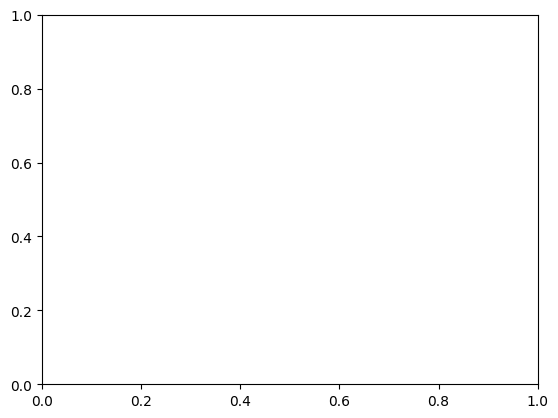

In [ ]:
import matplotlib.pyplot as plt
k = range(1,50)
plt.plot(k, train_scores)
plt.plot(k, test_scores)

plt.show()
# k=1 -> просто словарь для train

### Задача 2. Классификация вин

В этой задаче предлагается классифицировать три типа вина на классическом датасете **Wine**. Произведите подготовку данных и настройку модели самостоятельно. В цикле сравните точность ($Accuracy$) на тестовой выборке для двух способов нормализации (MinMaxScaler и StandardScaler) и для трех мер расстояния ('euclidean', 'manhattan' и 'cosine'). Результат оформите в виде таблички.

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_wine

X, y = load_wine(return_X_y=True)


In [ ]:
X.head()

AttributeError: 'numpy.ndarray' object has no attribute 'head'

In [ ]:
# считаем долю каждого класса среди knn
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [ ]:
scalers = [MinMaxScaler(), StandardScaler()] # 1 - от 0 до 1
distances = ['euclidean', 'manhattan', 'cosine']

train_scores = []
test_scores = []
for scaler in scalers:
  scaler.fit(X_train)
  X_train_sc = scaler.transform(X_train)
  X_test_sc = scaler.transform(X_test)

  for dist in distances:
    knn = KNeighborsClassifier(metric=dist)
    knn.fit(X_train_sc, y_train)

    y_train_pred = knn.predict(X_train_sc)
    y_test_pred = knn.predict(X_test_sc)

    train_score = accuracy_score(y_train, y_train_pred)
    test_score = accuracy_score(y_test, y_test_pred)
    train_scores.append(train_score)
    test_scores.append(test_score)

In [ ]:
pd.DataFrame(
    {'scaler': ['MinMax']*3 + ['Stand']*3,
     'metrics': distances*2,
     'train_acc': train_scores,
     'test_acc': test_scores}
)

,scaler,metrics,train_acc,test_acc
0,MinMax,euclidean,0.964789,0.972222
1,MinMax,manhattan,0.971831,0.972222
2,MinMax,cosine,0.964789,0.916667
3,Stand,euclidean,0.964789,0.972222
4,Stand,manhattan,0.978873,0.972222
5,Stand,cosine,0.957746,0.972222
